# Задача 7. numpy-массивы вместо списков

Все фотоны события хранятся в `numpy`-массивах, по строке на фотон:

| величина | метод | форма |
|---|---|---|
| направления | `Source.directions(E)` | `(n, 3)` |
| путь до стенки | `Detector.path_length(o, n)` | `(n,)` |
| выжил / поглощён | `Detector.survives(t)` | `(n,)`, bool |
| номер ФЭУ или −1 | `Detector.trace(o, n)` | `(n,)` |
| фотоны на каждом ФЭУ | `np.bincount(...)` | `(N,)` |
| ф.э. на каждом ФЭУ | `Detector.photoelectrons(hits)` | `(N,)` |

Ни один из этих методов не содержит цикла по фотонам — операции выполняются над целыми массивами. Для сравнения в `pure_python.py` написана та же модель на чистом Python: фотоны — кортежи в `list`, цикл по фотонам и по ФЭУ, модуль `math`/`random`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector
from source import Source
from pure_python import PyDetector, PySource
import random

L_att = 8.0
det = Detector(R=2.0, N=40, r=0.10, a=0.5, attenuation_length=L_att, rng=7)
src = Source(Y=10_000, rng=70)
pdet = PyDetector(R=2.0, N=40, r=0.10, a=0.5, attenuation_length=L_att)
psrc = PySource(Y=10_000)
random.seed(7)
o = np.array([0, 0, 0.5])

def timeit(f, repeat):
    t = time.perf_counter()
    for _ in range(repeat):
        out = f()
    return (time.perf_counter() - t) / repeat, out

## Сравнение по этапам (событие 1 МэВ, ~10⁴ фотонов)

In [2]:
E = 1.0
d_np = src.directions(E)
d_py = psrc.directions(E)
hits_np = np.bincount((idx := det.trace(o, d_np))[idx >= 0], minlength=det.N)
hits_py = [0] * pdet.N
for n in d_py:
    k = pdet.trace(tuple(o), n)
    if k >= 0: hits_py[k] += 1

stages = {
    "генерация":  (lambda: src.directions(E),          lambda: psrc.directions(E)),
    "пропагация": (lambda: det.trace(o, d_np),         lambda: [pdet.trace(tuple(o), n) for n in d_py]),
    "фотоэлектроны": (lambda: det.photoelectrons(hits_np), lambda: pdet.photoelectrons(hits_py)),
    "событие целиком": (lambda: det.response(o, src.directions(E)),
                        lambda: pdet.response(tuple(o), psrc.directions(E))),
}
rows = []
for name, (f_np, f_py) in stages.items():
    t_np, _ = timeit(f_np, 50)
    t_py, _ = timeit(f_py, 3)
    rows.append((name, t_py, t_np))
    print(f"{name:16s}: Python {t_py*1e3:9.3f} мс,  numpy {t_np*1e3:8.3f} мс,  выигрыш ×{t_py/t_np:7.1f}")

генерация       : Python     7.089 мс,  numpy    0.286 мс,  выигрыш ×   24.8


пропагация      : Python   359.217 мс,  numpy    3.756 мс,  выигрыш ×   95.6
фотоэлектроны   : Python     0.020 мс,  numpy    0.014 мс,  выигрыш ×    1.4


событие целиком : Python   336.212 мс,  numpy    4.014 мс,  выигрыш ×   83.8


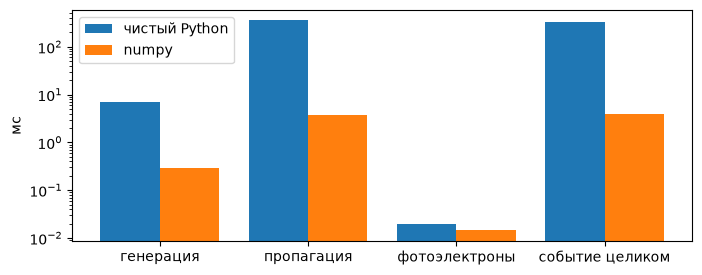

In [3]:
names = [r[0] for r in rows]
x = np.arange(len(rows))
plt.figure(figsize=(8, 3))
plt.bar(x - 0.2, [r[1]*1e3 for r in rows], 0.4, label='чистый Python')
plt.bar(x + 0.2, [r[2]*1e3 for r in rows], 0.4, label='numpy')
plt.xticks(x, names); plt.yscale('log'); plt.ylabel('мс'); plt.legend(); plt.show()

## Зависимость от числа фотонов

У numpy есть постоянные накладные расходы на каждый вызов (~десятки мкс), поэтому выигрыш растёт с размером массива, а для единичных фотонов numpy может проигрывать чистому Python.

n =        1: Python     0.024 мс, numpy   0.082 мс, ×   0.3
n =       10: Python     0.423 мс, numpy   0.082 мс, ×   5.1
n =      100: Python     3.391 мс, numpy   0.105 мс, ×  32.2
n =     1000: Python    33.963 мс, numpy   0.314 мс, × 108.2
n =    10000: Python   335.769 мс, numpy   4.138 мс, ×  81.1
n =    30000: Python  1032.748 мс, numpy  12.677 мс, ×  81.5


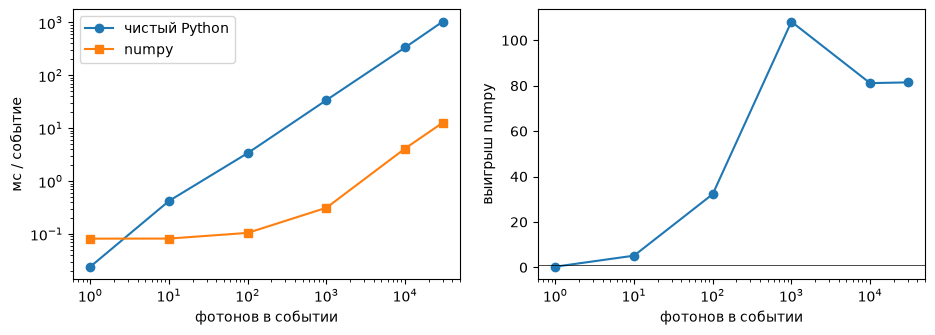

In [4]:
energies = np.array([0.0001, 0.001, 0.01, 0.1, 1.0, 3.0])
t_np, t_py = [], []
for E in energies:
    t_np.append(timeit(lambda: det.response(o, src.directions(E)), 30)[0])
    t_py.append(timeit(lambda: pdet.response(tuple(o), psrc.directions(E)), 3 if E > 0.5 else 10)[0])
t_np, t_py = np.array(t_np), np.array(t_py)
n_ph = energies * src.Y
for n, a_, b_ in zip(n_ph, t_py, t_np):
    print(f"n = {n:8.0f}: Python {a_*1e3:9.3f} мс, numpy {b_*1e3:7.3f} мс, ×{a_/b_:6.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].loglog(n_ph, t_py * 1e3, 'o-', label='чистый Python')
ax[0].loglog(n_ph, t_np * 1e3, 's-', label='numpy')
ax[0].set_xlabel('фотонов в событии'); ax[0].set_ylabel('мс / событие'); ax[0].legend()
ax[1].semilogx(n_ph, t_py / t_np, 'o-'); ax[1].axhline(1, color='k', lw=0.5)
ax[1].set_xlabel('фотонов в событии'); ax[1].set_ylabel('выигрыш numpy')
plt.show()

## Обе реализации дают одинаковую физику

(300 событий на Python: 105.8 с)


numpy:  <Q> = 97.87 ± 0.70, σ = 12.05
Python: <Q> = 96.77 ± 0.71, σ = 12.29
KS p-value: 0.3958302746926979


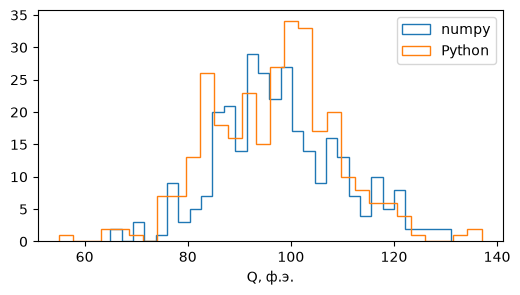

In [5]:
n_ev = 300
Q_np = np.array([det.response(o, src.directions(1.0)).sum() for _ in range(n_ev)])
t = time.perf_counter()
Q_py = np.array([sum(pdet.response(tuple(o), psrc.directions(1.0))) for _ in range(n_ev)])
print(f"(300 событий на Python: {time.perf_counter() - t:.1f} с)")
from scipy import stats
print(f"numpy:  <Q> = {Q_np.mean():.2f} ± {Q_np.std()/np.sqrt(n_ev):.2f}, σ = {Q_np.std():.2f}")
print(f"Python: <Q> = {Q_py.mean():.2f} ± {Q_py.std()/np.sqrt(n_ev):.2f}, σ = {Q_py.std():.2f}")
print("KS p-value:", stats.ks_2samp(Q_np, Q_py).pvalue)
plt.figure(figsize=(6, 3))
plt.hist(Q_np, bins=30, histtype='step', label='numpy'); plt.hist(Q_py, bins=30, histtype='step', label='Python')
plt.xlabel('Q, ф.э.'); plt.legend(); plt.show()

**Выводы.**
- Событие 1 МэВ (~10⁴ фотонов): чистый Python ≈ 335 мс, numpy ≈ 4 мс — выигрыш **≈ 80 раз**. 1000 событий: ~5 минут против ~4 секунд.
- Больше всего выигрывает пропагация (×96): в Python для каждого фотона перебираются все 40 ФЭУ, т.е. ~4·10⁵ итераций интерпретатора на событие; в numpy это одно матричное умножение `(n, 3) @ (3, N)`.
- Генерация направлений ускоряется в ≈25 раз. Розыгрыш фотоэлектронов почти не ускоряется: там всего N = 40 чисел, и время определяется накладными расходами вызова, а не вычислениями.
- Выигрыш растёт с числом фотонов и выходит на плато ≈ ×80–110 при n ≳ 10³. Для единичного фотона numpy в ~3 раза **медленнее** — вызов функции numpy стоит ~десятки мкс. Поэтому массивы выгодны только тогда, когда операция применяется сразу ко многим элементам (ср. генератор пачками в задаче 5).
- Распределения заряда двух реализаций согласуются (KS p ≈ 0.4; средние отличаются на 1.1σ при 300 событиях). На одних и тех же лучах обе версии выдают одинаковые номера ФЭУ — это проверяет тест `test_pure_python_matches_numpy`.